<a href="https://colab.research.google.com/github/tomvangasse/ATLAS-top-tagging-ML-project/blob/main/XGboost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# XGboost
At it's core, XGboost is a decision tree, asking questions about the data and then taking a certain path. On it's own, one tree is weak, it can't solve a problem as complex as top-tagging.

Gradient boosting builds trees one after the other, each one is trained to get gradually closer to a better result.

e**X**treme **G**radient boosting is just an implementation of this idea, it adds a few features that improve performance.

## Mounting Google drive and dowloading the dataset

In [2]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/cern_data

Mounted at /content/drive


In [6]:
!pip install -q cernopendata-client
!cernopendata-client get-file-locations --recid 80030 --protocol http | grep test_nominal | head -5

http://opendata.cern.ch/eos/opendata/atlas/datascience/CERN-EP-2024-159/test_nominal_000.h5.gz
http://opendata.cern.ch/eos/opendata/atlas/datascience/CERN-EP-2024-159/test_nominal_001.h5.gz
http://opendata.cern.ch/eos/opendata/atlas/datascience/CERN-EP-2024-159/test_nominal_010.h5.gz
http://opendata.cern.ch/eos/opendata/atlas/datascience/CERN-EP-2024-159/test_nominal_100.h5.gz
http://opendata.cern.ch/eos/opendata/atlas/datascience/CERN-EP-2024-159/test_nominal_101.h5.gz


In [7]:
%cd /content/drive/MyDrive/cern_data
!wget -c "http://opendata.cern.ch/eos/opendata/atlas/datascience/CERN-EP-2024-159/test_nominal_000.h5.gz"

/content/drive/MyDrive/cern_data
--2026-10-25 11:16:29--  http://opendata.cern.ch/eos/opendata/atlas/datascience/CERN-EP-2024-159/test_nominal_000.h5.gz
Resolving opendata.cern.ch (opendata.cern.ch)... 137.138.6.31, 2001:1458:201:8b::100:1c8
Connecting to opendata.cern.ch (opendata.cern.ch)|137.138.6.31|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 96662577 (92M) [application/octet-stream]
Saving to: ‘test_nominal_000.h5.gz’

test_nominal_000.h5 100%[===================>]  92.18M  1.50MB/s    in 2m 28s  

2026-10-25 11:18:58 (636 KB/s) - ‘test_nominal_000.h5.gz’ saved [96662577/96662577]



In [8]:
!gunzip *test_nominal*.h5.gz
!ls -lh

total 800M
-rw------- 1 root root 400M Jul 25  2024 test_nominal_000.h5
-rw------- 1 root root 401M Jul 25  2024 train_nominal_000.h5


## Loading and setting up the data



In [19]:
import pandas as pd
import h5py
import numpy as np
DATA = "/content/drive/MyDrive/cern_data/"


Loading the data and getting the feature names

In [20]:
def load(path, n=None): # n is how many jets to read from the dataset - None is default, reads all of them
    with h5py.File(path, "r") as f:
        return pd.DataFrame({k: f[k][:n] for k in f.keys() if f[k].ndim == 1})
            # only takes arrays with one data point per jet, so it can fit into a flat table
            # reads the first n jets and returns them as a dictionary

train_df = load(DATA + "train_nominal_000.h5", n=1_000_000)
test_df  = load(DATA + "test_nominal_000.h5")
print(train_df.shape, test_df.shape)
print(train_df.columns.tolist())


(100000, 22) (100000, 21)
['EventInfo_mcEventNumber', 'fjet_C2', 'fjet_D2', 'fjet_ECF1', 'fjet_ECF2', 'fjet_ECF3', 'fjet_L2', 'fjet_L3', 'fjet_Qw', 'fjet_Split12', 'fjet_Split23', 'fjet_Tau1_wta', 'fjet_Tau2_wta', 'fjet_Tau3_wta', 'fjet_Tau4_wta', 'fjet_ThrustMaj', 'fjet_eta', 'fjet_m', 'fjet_phi', 'fjet_pt', 'labels', 'training_weights']


In [21]:
LABEL  = "labels"
WEIGHT = "training_weights"
FEATURES = [    # These 15 features were chosen becuase they are the most important for determining top jets
    "fjet_C2",
    "fjet_D2",
    "fjet_ECF1",
    "fjet_ECF2",
    "fjet_ECF3",
    "fjet_L2",
    "fjet_L3",
    "fjet_Qw",
    "fjet_Split12",
    "fjet_Split23",
    "fjet_Tau1_wta",
    "fjet_Tau2_wta",
    "fjet_Tau3_wta",
    "fjet_Tau4_wta",
    "fjet_ThrustMaj",
]
print(len(FEATURES))  # should print 15


15


In [22]:
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val, w_tr, w_val = train_test_split(
    train_df[FEATURES],
    train_df[LABEL],
    train_df[WEIGHT],
    test_size=0.2,
    random_state=1,
    stratify=train_df[LABEL],   # keeps the same top-quark/QCD ratio in both parts
)


## Training the model

This cell creates an untrained model with settings we can tweak

In [39]:
import xgboost as xgb

model = xgb.XGBClassifier(
    n_estimators=1000,
    learning_rate=0.1,
    max_depth=4,
    tree_method="hist",
    early_stopping_rounds=50,
    eval_metric="logloss",
)


Then we train the model using the training data

In [40]:
model.fit(
    X_tr, y_tr,
    sample_weight=w_tr,
    eval_set=[(X_tr, y_tr), (X_val, y_val)],
    sample_weight_eval_set=[w_tr, w_val],
    verbose=100,    # prints scores every 100 trees
)
print("Best number of trees:", model.best_iteration)


[0]	validation_0-logloss:0.65428	validation_1-logloss:0.65431
[100]	validation_0-logloss:0.36057	validation_1-logloss:0.37141
[200]	validation_0-logloss:0.34140	validation_1-logloss:0.36185
[300]	validation_0-logloss:0.32835	validation_1-logloss:0.35796
[400]	validation_0-logloss:0.31840	validation_1-logloss:0.35625
[500]	validation_0-logloss:0.30981	validation_1-logloss:0.35576
[578]	validation_0-logloss:0.30381	validation_1-logloss:0.35576
Best number of trees: 528


## Creating a learning curve for the model
If both curves fall together, that means the model is learning patterns.

If training falls while validation rises or plateaus, that means the model may be overfitting, the model is 'memorising' the training data instead of learning patterns.
Try lowering the max_depth in the model settings and re-training.

If neither lines fall, the model may be underfitting, try increasing the max_depth or increasing the number of trees.

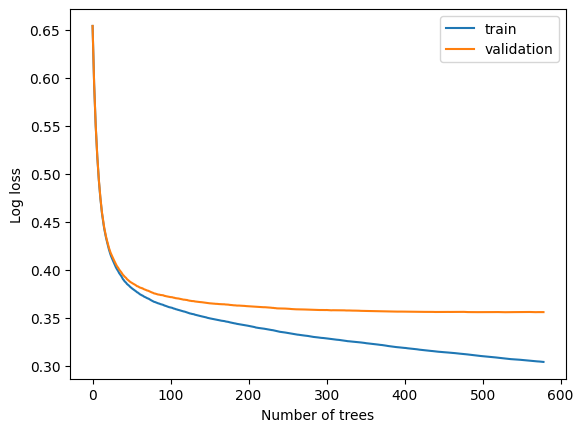

In [41]:
import matplotlib.pyplot as plt

results = model.evals_result()  # returns the log loss for every tre
plt.plot(results["validation_0"]["logloss"], label="train")
plt.plot(results["validation_1"]["logloss"], label="validation")
    # XGboost labels training and validation as validation_0 and validation_1 respectively

plt.xlabel("Number of trees")
plt.ylabel("Log loss")
plt.legend()
plt.show()


## Using the test set to evaluate the model

For each test jet, `predict_proba` gives the model's probability that the jet came from a top quark.

Two metrics are reported:
- AUC:
    - The area under the ROC curve. It is the probability that a random top jet scores higher than a random QCD jet. Closer to 1 is better.
- Background rejection:
    - The background rejection at 50% and 80% signal efficiency: the threshold is set to keep 50% (or 80%) of top jets, and the rejection is `1 / (the fraction of QCD jets wrongly kept)`. For example, a rejection of 50 means 1 in 50 QCD jets passes.

### My results were:

AUC: 0.9263927857007417

Rejection at 50% signal efficiency: 36.25893508388038

Rejection at 80% signal efficiency: 8.640883017556058


In [46]:
from sklearn.metrics import roc_auc_score, roc_curve

y_te = test_df[LABEL]
w_te = None     # the dataset doesn't have weights, so every jet counts the same
score = model.predict_proba(test_df[FEATURES])[:, 1]
    # score holds the top-quark probability

def background_rejection(labels, scores, weights, signal_efficiency):
    fpr, tpr, _ = roc_curve(labels, scores, sample_weight=weights)  # tpr/fpr is the true/false positive rate
    return 1 / np.interp(signal_efficiency, tpr, fpr)


print("AUC:", roc_auc_score(y_te, score, sample_weight=w_te))
for eff in (0.5, 0.8):
    print(f"Rejection at {eff:.0%} signal efficiency:",
          background_rejection(y_te, score, w_te, eff))



AUC: 0.9263927857007417
Rejection at 50% signal efficiency: 36.25893508388038
Rejection at 80% signal efficiency: 8.640883017556058


## Plotting the test results

### Score distribution
What it should show:

QCD piled up near 0, top piled up near 1, with little overlap. The overlap region is where the tagger is confused.

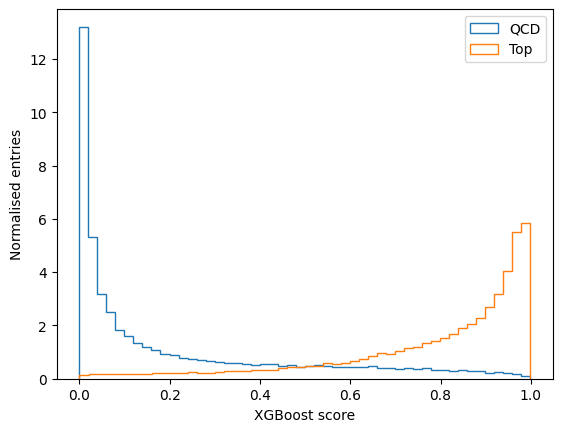

In [47]:
plt.hist(score[y_te == 0], bins=50, histtype="step", density=True, label="QCD")
plt.hist(score[y_te == 1], bins=50, histtype="step", density=True, label="Top")
plt.xlabel("XGBoost score")
plt.ylabel("Normalised entries")
plt.legend()
plt.show()


### Rejection against signal efficiency

#### Explaination
Recall that rejection is `1/(false positive rate)`

In particle physics, plotting the false positive rate is important, because the number of background jets is so much higher than signal, so what matters is the difference between letting through 1% of background vs 0.5%.

A strict threshold (left side, low efficiency) keeps only the jets the model is most sure are tops. You lose many real tops, but almost no QCD gets through, so rejection is high.

A loose threshold (right side, high efficiency) keeps almost all tops, but lets lots of QCD through too, so rejection falls. At 100% efficiency you keep everything, and the rejection drops to 1.

#### What it should show:

A curve that starts high on the left and falls smoothly to the right, on the log-scale y-axis.

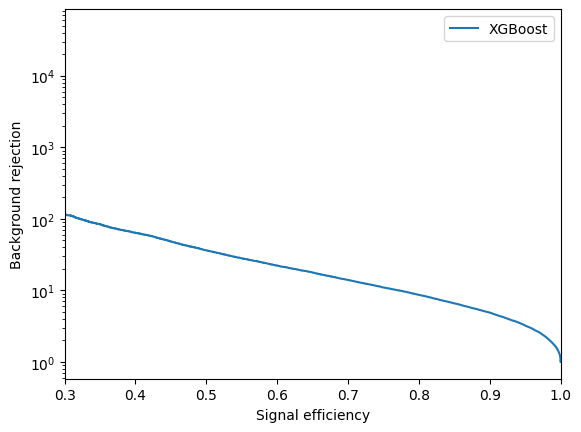

In [49]:
fpr, tpr, _ = roc_curve(y_te, score, sample_weight=w_te)
mask = fpr > 0
plt.plot(tpr[mask], 1 / fpr[mask], label="XGBoost")
plt.yscale("log")
plt.xlabel("Signal efficiency")
plt.ylabel("Background rejection")
plt.xlim(0.3, 1)
plt.legend()
plt.show()

## Explaining the model with SHAP

Rows are the features of quark jets, ordered from most to least important

Colour: the feature's value, red is high, blue is low.

Horizontal position: left of the line means the jet is being pushed towards 'QCD'. Right of the line means the jet is pushed towards 'top'.

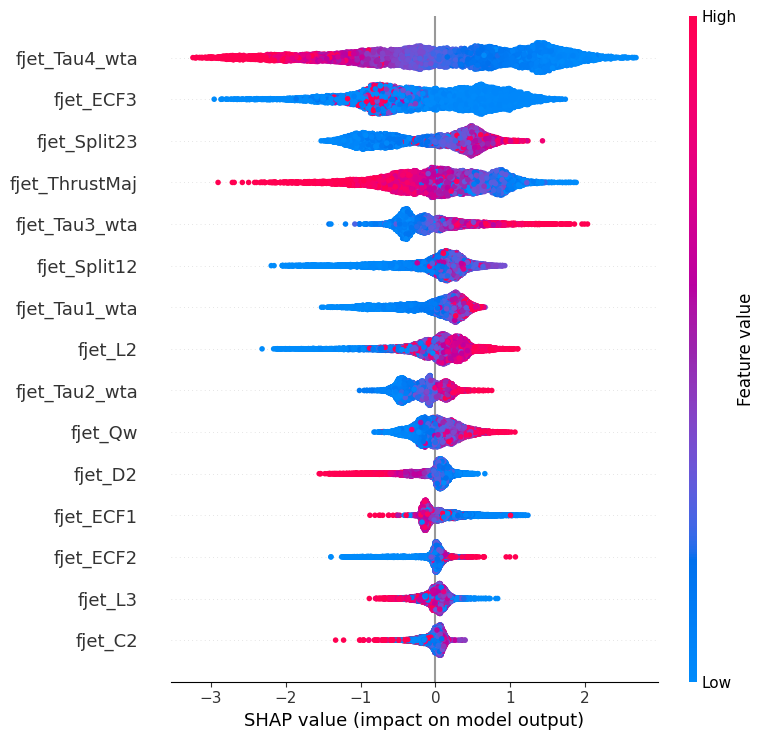

In [52]:
!pip install -q shap
import shap

sample = test_df[FEATURES].sample(5000, random_state=0)
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(sample)
shap.summary_plot(shap_values, sample)

## Saving the model


In [53]:
import numpy as np
DATA = "/content/drive/MyDrive/cern_data/"

np.save(DATA + "preds_xgb_test_nominal.npy", score) # Saving the score as a np array
model.save_model(DATA + "xgb_model.json")   # The trained model

!ls -lh /content/drive/MyDrive/cern_data/

total 802M
-rw------- 1 root root 391K Oct 25 13:01 preds_xgb_test_nominal.npy
-rw------- 1 root root 400M Jul 25  2024 test_nominal_000.h5
-rw------- 1 root root 401M Jul 25  2024 train_nominal_000.h5
-rw------- 1 root root 1.2M Oct 25 13:01 xgb_model.json
